## instruction
This program is about prediction of the chance to have lung cancer.
in this program we have target so we need to use supervised learning methods.
the data is classification so i used this three methods:
KNN , SVM , Decision Tree
And i tryed them and i did some tests to find out which one is better and has better accuracy

## in this cell i import the required things that i need

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sb
from sklearn.neighbors import  KNeighborsClassifier
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_score,StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,precision_score, recall_score, f1_score
from sklearn.tree import DecisionTreeClassifier,plot_tree,DecisionTreeRegressor
from sklearn.svm import SVC
import tkinter as tk
from tkinter import ttk, messagebox
from scipy.stats import norm, skew 
import warnings
warnings.filterwarnings("ignore")

## Reading the data

In [2]:
data=pd.read_csv(r"cancer patient data sets.csv")

In [3]:
data.head()

,index,Patient Id,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,0,P1,33,1,2,4,5,4,3,2,...,3,4,2,2,3,1,2,3,4,Low
1,1,P10,17,1,3,1,5,3,4,2,...,1,3,7,8,6,2,1,7,2,Medium
2,2,P100,35,1,4,5,6,5,5,4,...,8,7,9,2,1,4,6,7,2,High
3,3,P1000,37,1,7,7,7,7,6,7,...,4,2,3,1,4,5,6,7,5,High
4,4,P101,46,1,6,8,7,7,7,6,...,3,2,4,1,4,2,4,2,3,High


## delleting the columns that we dont need
index and id are not the data that we need in this program

In [4]:
data.drop("index",axis=1,inplace=True)
data.drop("Patient Id",axis=1,inplace=True)

In [5]:
data.head()

,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,...,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring,Level
0,33,1,2,4,5,4,3,2,2,4,...,3,4,2,2,3,1,2,3,4,Low
1,17,1,3,1,5,3,4,2,2,2,...,1,3,7,8,6,2,1,7,2,Medium
2,35,1,4,5,6,5,5,4,6,7,...,8,7,9,2,1,4,6,7,2,High
3,37,1,7,7,7,7,6,7,7,7,...,4,2,3,1,4,5,6,7,5,High
4,46,1,6,8,7,7,7,6,7,7,...,3,2,4,1,4,2,4,2,3,High


## Checking if we have null datas

In [6]:
data.isnull().sum()

Age                         0
Gender                      0
Air Pollution               0
Alcohol use                 0
Dust Allergy                0
OccuPational Hazards        0
Genetic Risk                0
chronic Lung Disease        0
Balanced Diet               0
Obesity                     0
Smoking                     0
Passive Smoker              0
Chest Pain                  0
Coughing of Blood           0
Fatigue                     0
Weight Loss                 0
Shortness of Breath         0
Wheezing                    0
Swallowing Difficulty       0
Clubbing of Finger Nails    0
Frequent Cold               0
Dry Cough                   0
Snoring                     0
Level                       0
dtype: int64

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype 
---  ------                    --------------  ----- 
 0   Age                       1000 non-null   int64 
 1   Gender                    1000 non-null   int64 
 2   Air Pollution             1000 non-null   int64 
 3   Alcohol use               1000 non-null   int64 
 4   Dust Allergy              1000 non-null   int64 
 5   OccuPational Hazards      1000 non-null   int64 
 6   Genetic Risk              1000 non-null   int64 
 7   chronic Lung Disease      1000 non-null   int64 
 8   Balanced Diet             1000 non-null   int64 
 9   Obesity                   1000 non-null   int64 
 10  Smoking                   1000 non-null   int64 
 11  Passive Smoker            1000 non-null   int64 
 12  Chest Pain                1000 non-null   int64 
 13  Coughing of Blood         1000 non-null   int64 
 14  Fatigue                  

## Cheking and delliting duplicate datas

In [8]:
data.duplicated().sum()

848

In [9]:
data = data.drop_duplicates().reset_index(drop=True)

In [10]:
data.describe()

,Age,Gender,Air Pollution,Alcohol use,Dust Allergy,OccuPational Hazards,Genetic Risk,chronic Lung Disease,Balanced Diet,Obesity,...,Coughing of Blood,Fatigue,Weight Loss,Shortness of Breath,Wheezing,Swallowing Difficulty,Clubbing of Finger Nails,Frequent Cold,Dry Cough,Snoring
count,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,...,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000,152.000000
mean,38.236842,1.414474,3.717105,4.480263,5.046053,4.710526,4.486842,4.243421,4.427632,4.414474,...,4.796053,3.763158,3.828947,4.269737,3.776316,3.750000,3.894737,3.480263,3.684211,2.921053
std,11.798382,0.494259,1.978084,2.601503,2.027424,2.158095,2.143794,1.880527,2.151857,2.120365,...,2.453107,2.230840,2.233924,2.263943,2.036740,2.196475,2.344948,1.848466,2.047195,1.542022
min,14.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000
25%,28.000000,1.000000,2.000000,2.000000,3.750000,3.000000,2.000000,3.000000,2.000000,3.000000,...,3.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000,2.000000
50%,37.000000,1.000000,3.000000,5.000000,6.000000,5.000000,5.000000,4.000000,4.000000,4.000000,...,4.000000,3.000000,3.000000,4.000000,4.000000,4.000000,4.000000,3.000000,3.000000,3.000000
75%,46.000000,2.000000,6.000000,7.000000,7.000000,7.000000,7.000000,6.000000,7.000000,7.000000,...,7.000000,5.000000,6.000000,6.000000,5.000000,5.000000,5.000000,5.000000,5.000000,4.000000
max,73.000000,2.000000,8.000000,8.000000,8.000000,8.000000,7.000000,7.000000,7.000000,7.000000,...,9.000000,9.000000,8.000000,9.000000,8.000000,8.000000,9.000000,7.000000,7.000000,7.000000


## Counting that how many Levels we have

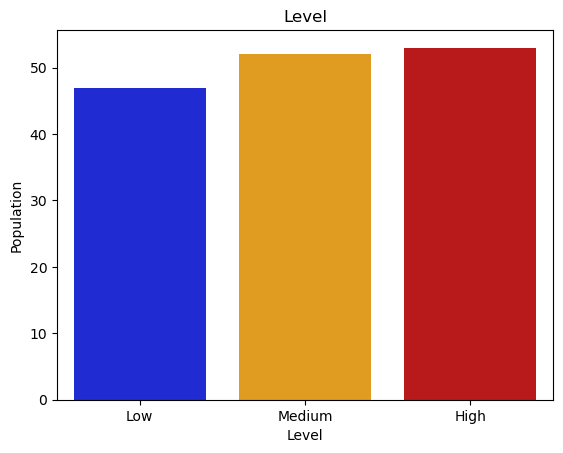

In [11]:
sb.countplot(x="Level",palette=["#0212EE","#FFA500","#D20001"],data=data)
plt.title("Level")
plt.ylabel("Population")
plt.show()

## Boxplot for each feature

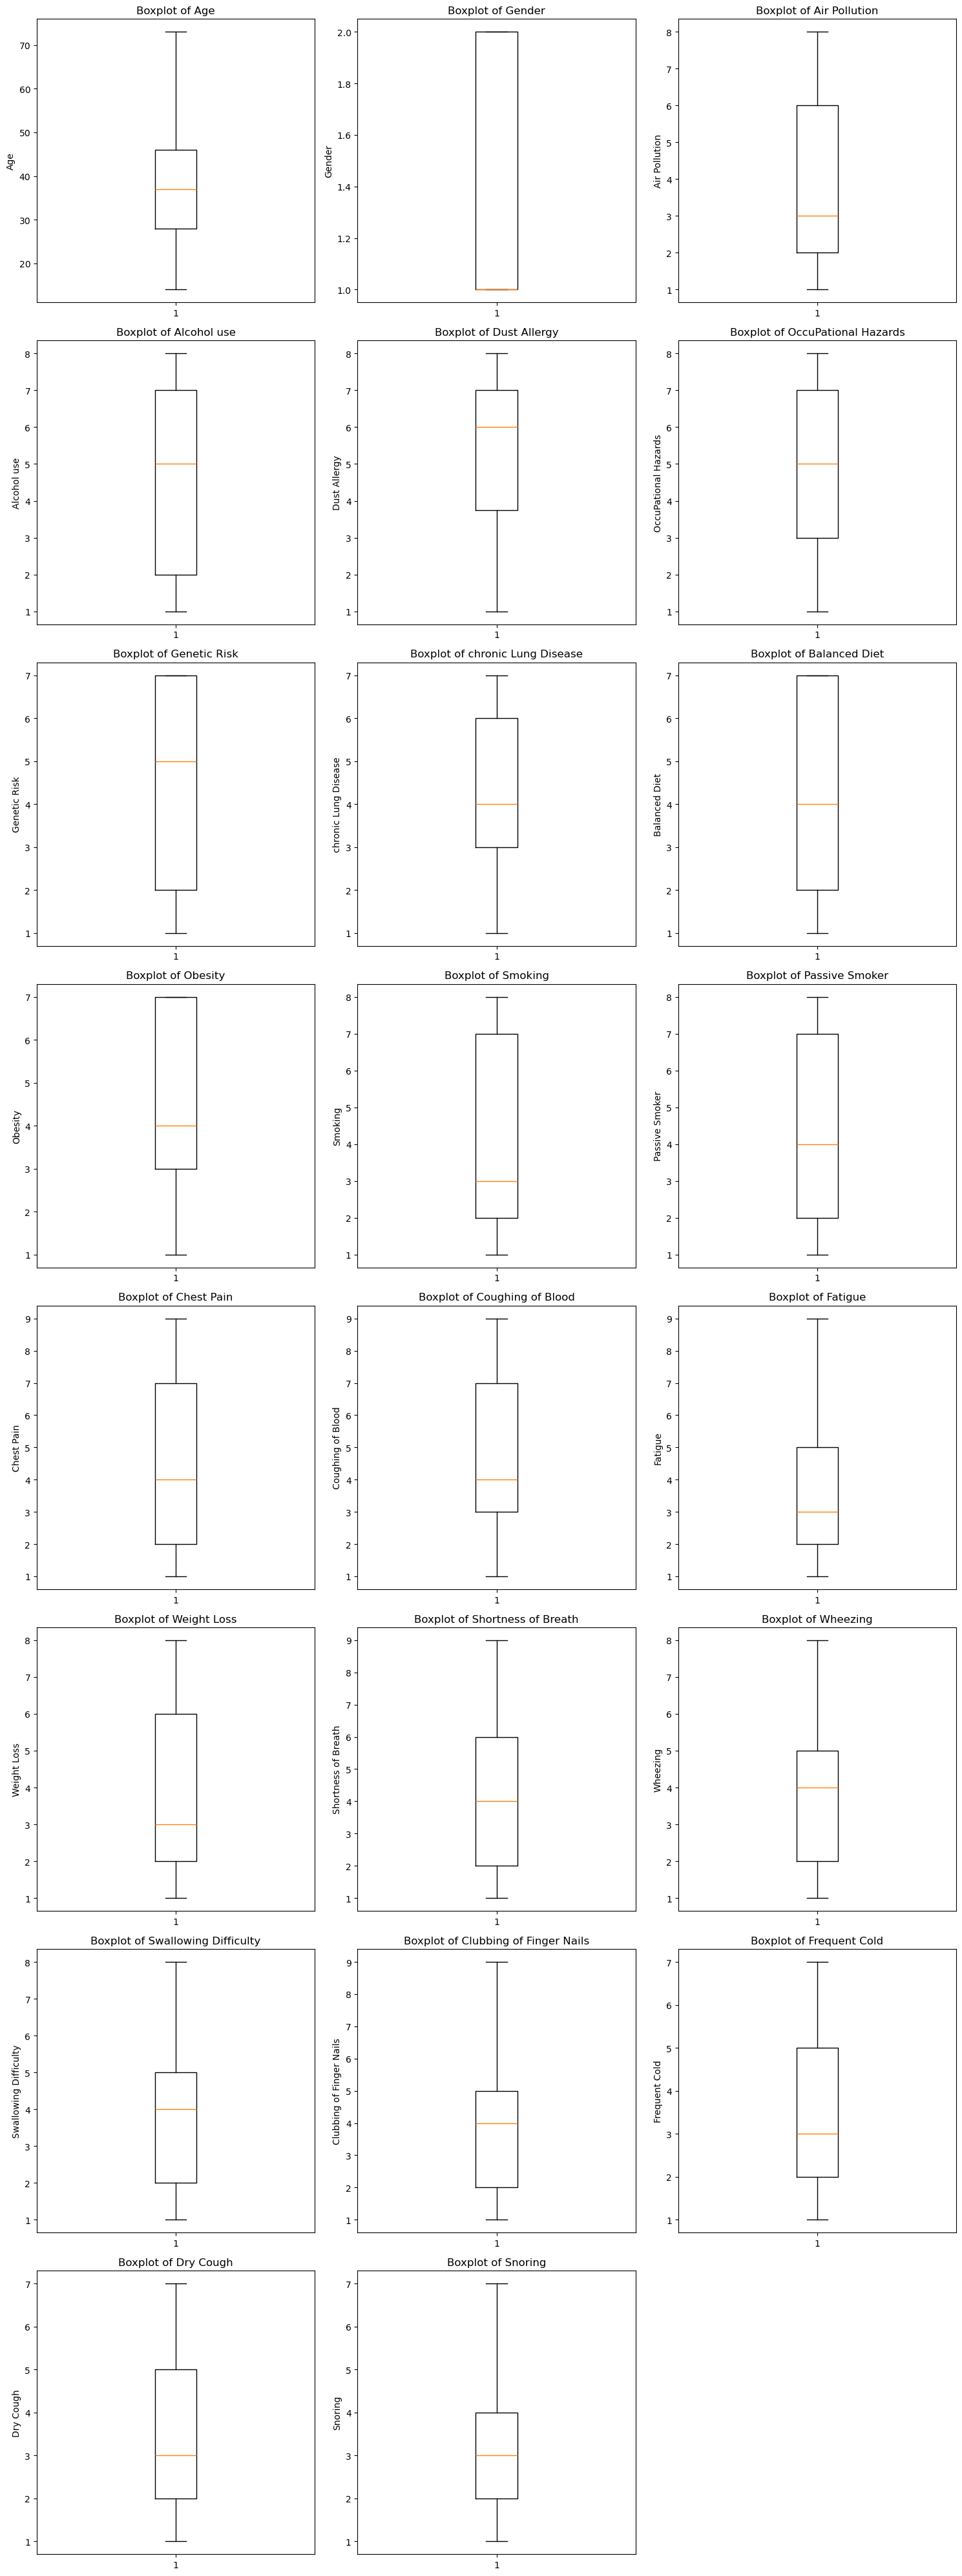

In [12]:
cols = data.columns[0:-1].tolist()
n = len(cols)
ncols = 3
nrows = -(-n // ncols) 

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].boxplot(data[col].dropna())
    axes[i].set_title(f"Boxplot of {col}")
    axes[i].set_ylabel(col)

for j in range(len(cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Histogram for each feature

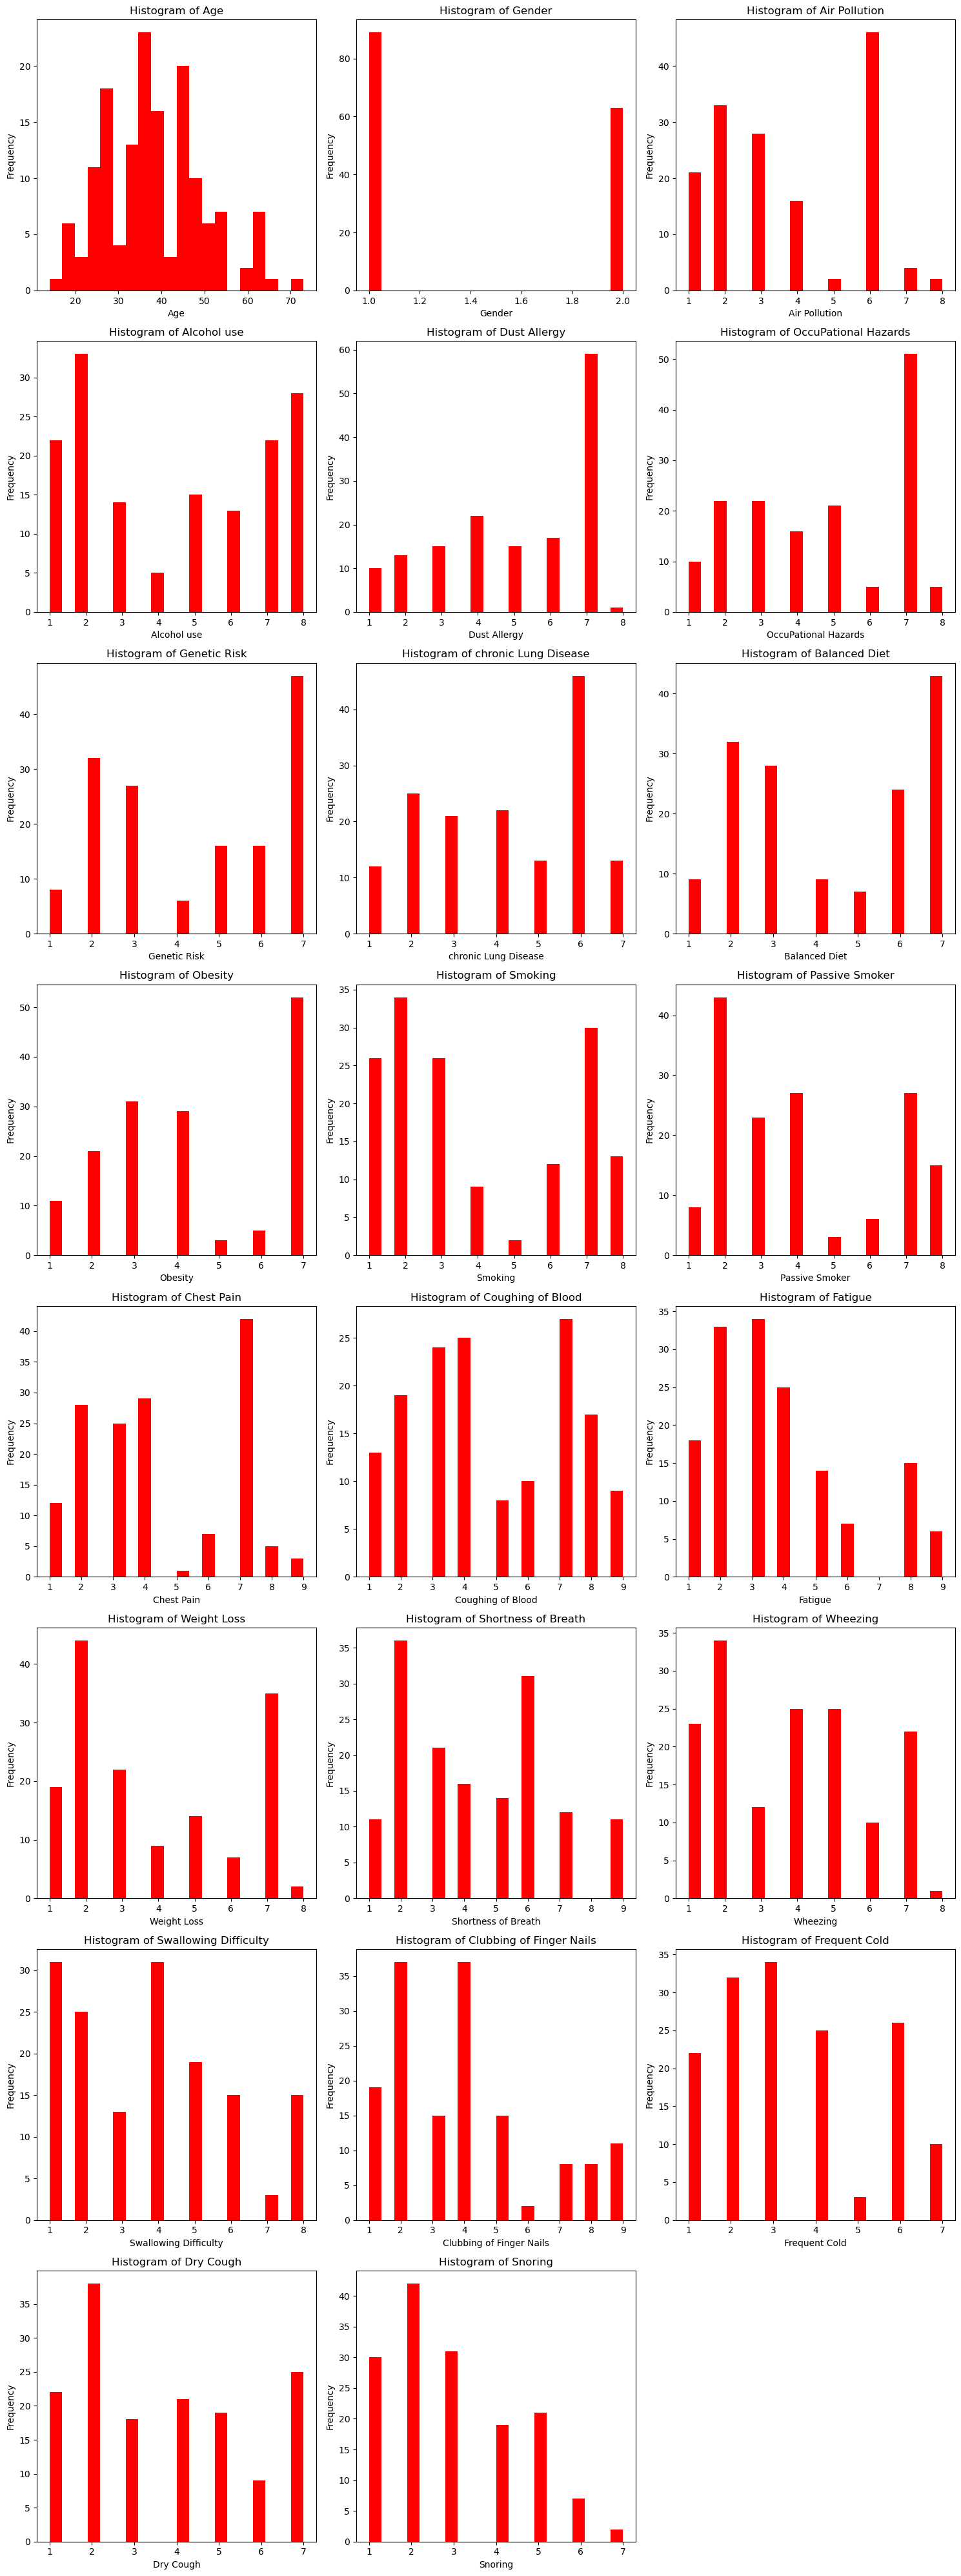

In [13]:
cols = data.columns[0:-1].tolist()
n = len(cols)
ncols = 3
nrows = -(-n // ncols) 

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 5*nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    axes[i].hist(data[col], bins=20, color="red")
    axes[i].set_title(f"Histogram of {col}")
    axes[i].set_xlabel(col)
    axes[i].set_ylabel("Frequency")

for j in range(len(cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## Pie Chart for each feature

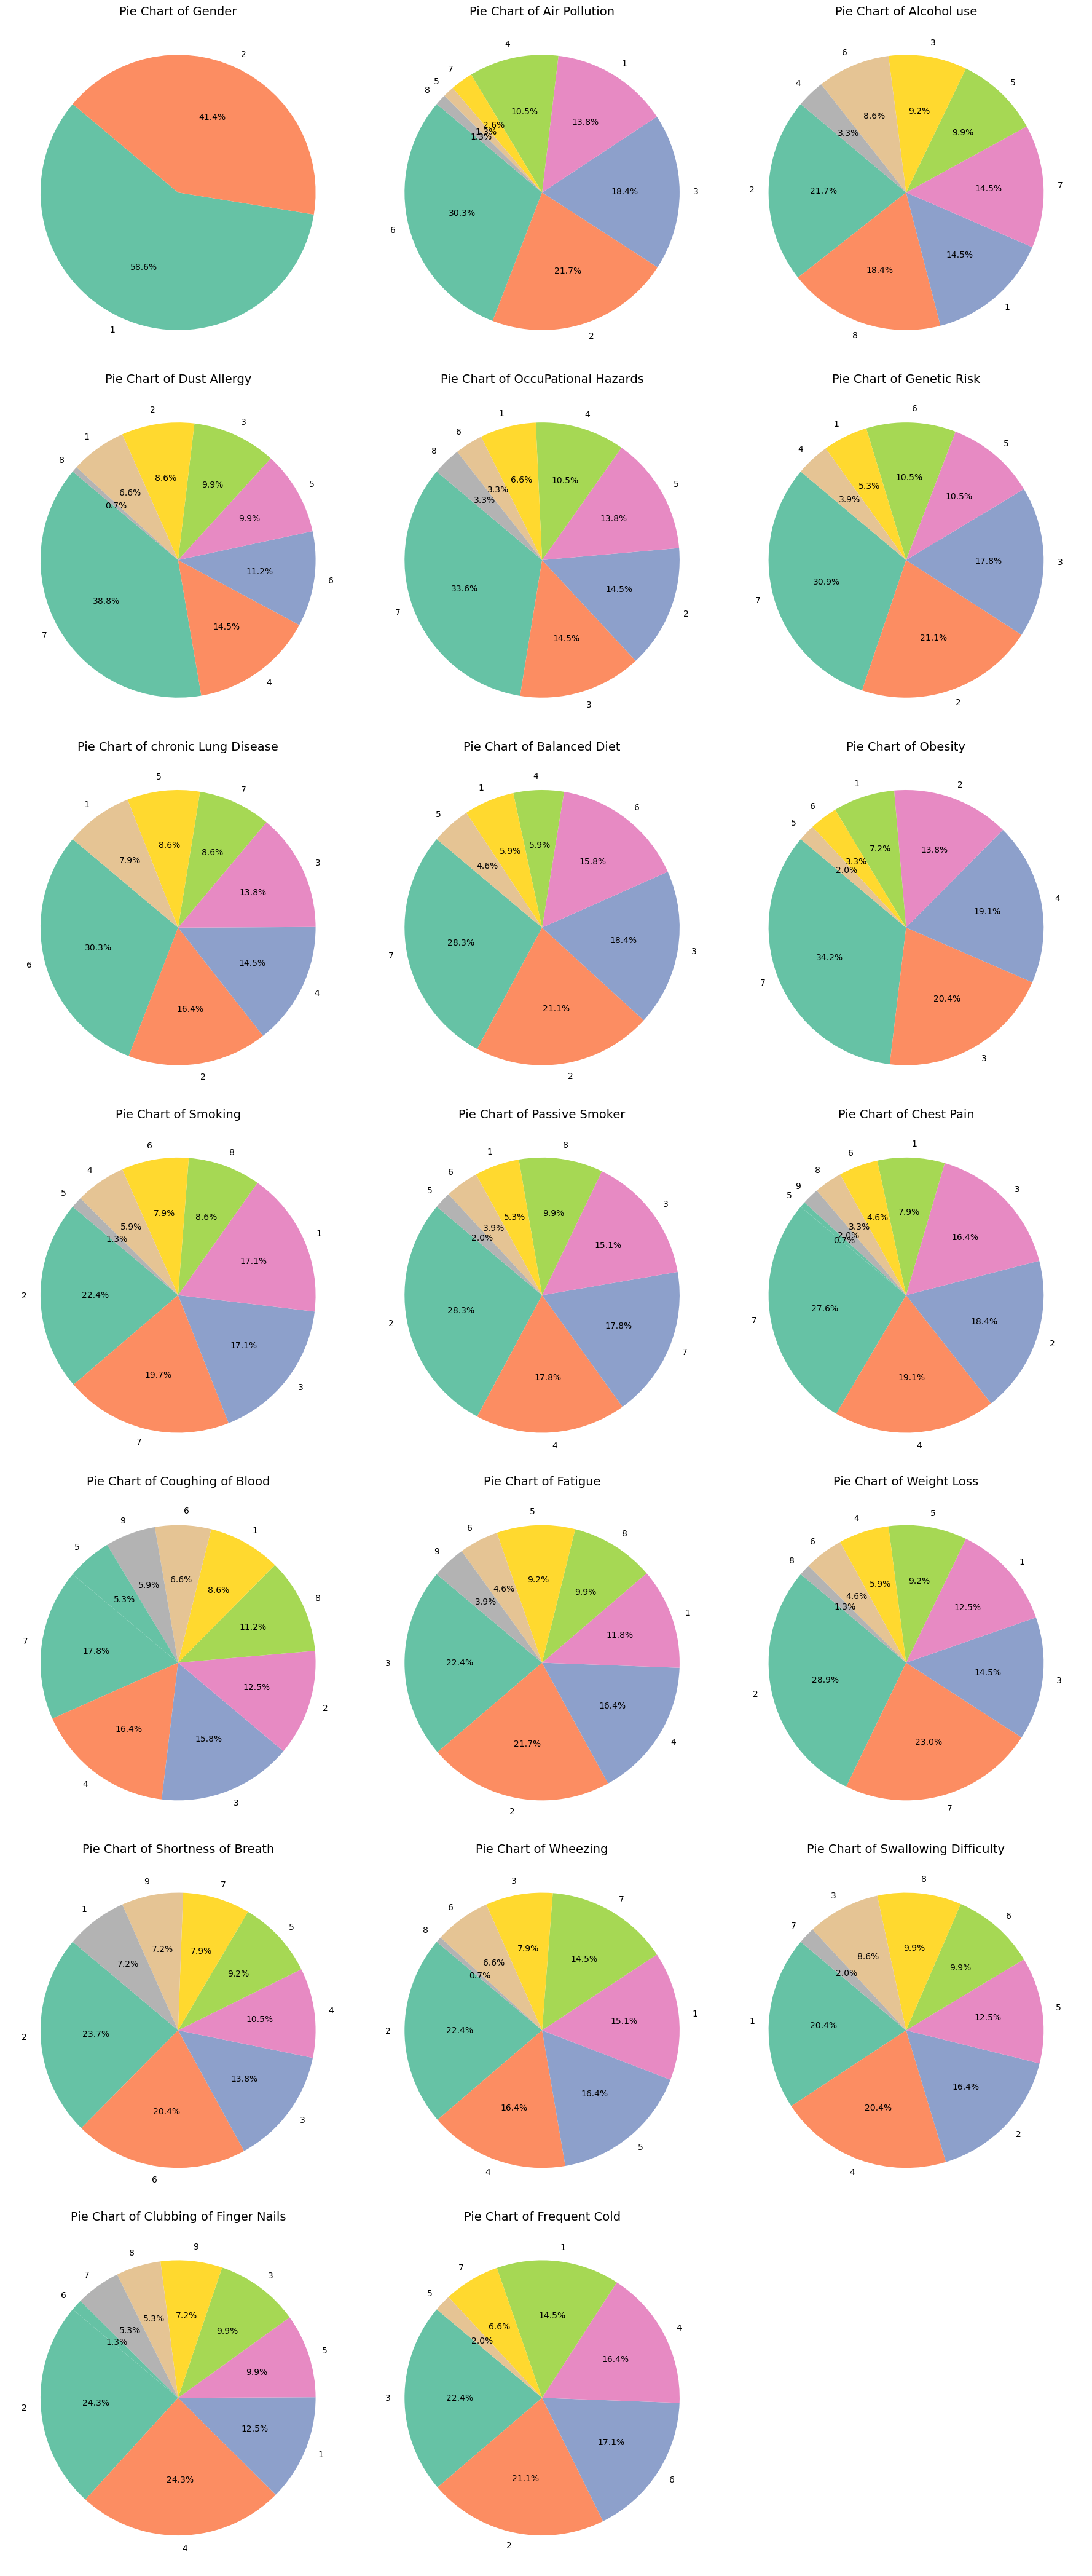

In [14]:
cols = [col for col in data.columns[1:-3].tolist() if col in data.columns]
n = len(cols)
ncols = 3
nrows = -(-n // ncols) 

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(6*ncols, 6*nrows))
axes = axes.flatten()

for i, col in enumerate(cols):
    counts = data[col].value_counts()
    axes[i].pie(
        counts,
        labels=counts.index,
        autopct='%1.1f%%',
        startangle=140,
        colors=plt.cm.Set2.colors
    )
    axes[i].set_title(f"Pie Chart of {col}", fontsize=14)

for j in range(len(cols), len(axes)):
    axes[j].axis("off")

plt.tight_layout()
plt.show()

## what impact each feature has on the target
as we can see Obesity and Coughing Blood and Alcohol use has the most effect on the Lung Cancer

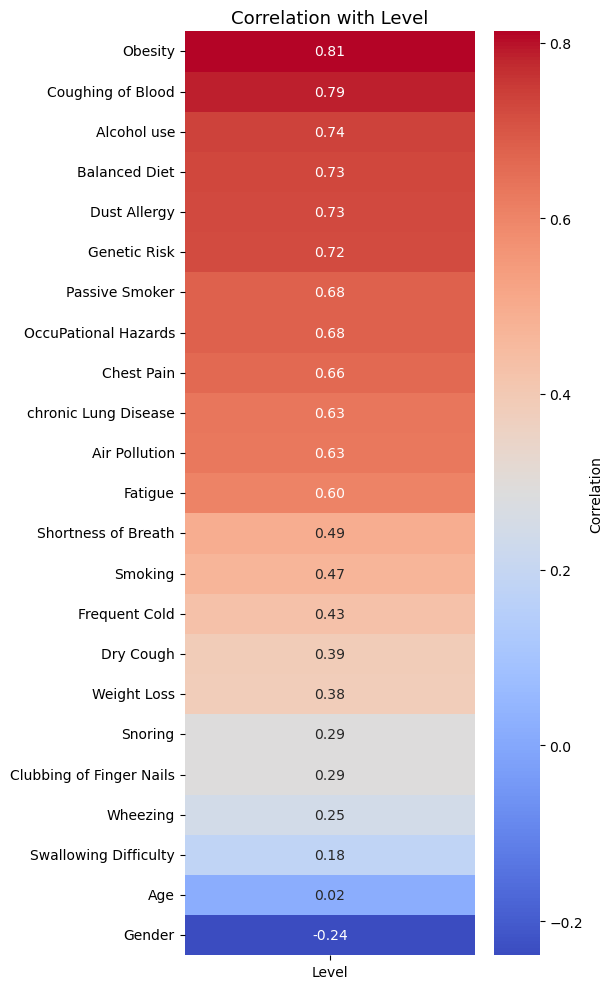

In [15]:
data2=data.copy()
level={'Medium':1,'Low':0,'High':2}
data2["Level"]=data2["Level"].map(level)
target = "Level"
corr_target = data2.corr()[target].drop(target).sort_values(ascending=False)

plt.figure(figsize=(6,10))
sb.heatmap(corr_target.to_frame(), annot=True, fmt=".2f", cmap="coolwarm",
           cbar_kws={"label": "Correlation"})
plt.title(f"Correlation with {target}", fontsize=13)
plt.tight_layout()
plt.show()

## what impact each feature has on the other features and target
as we can see Obesity and Coughing Blood and Alcohol use has the most effect on the Lung Cancer

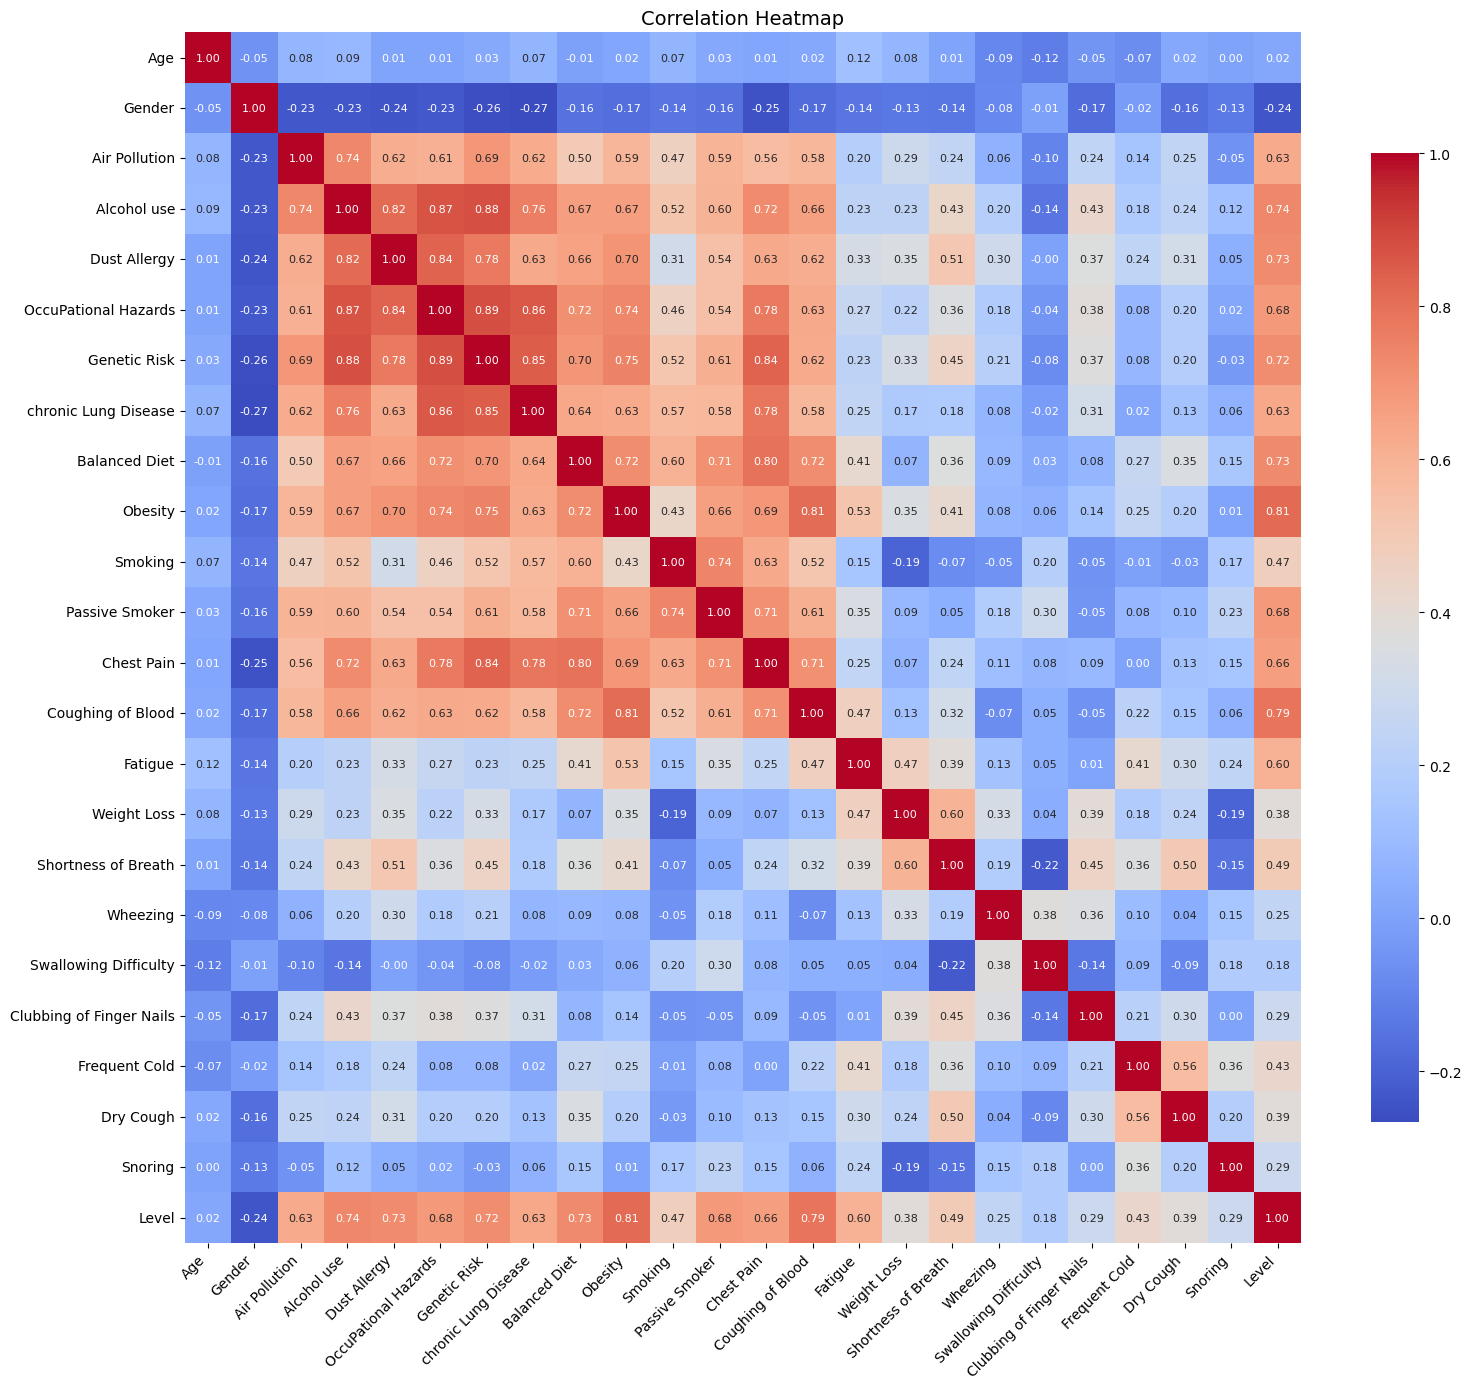

In [16]:
plt.figure(figsize=(16,14))
sb.heatmap(data2.corr(), annot=True, fmt=".2f", cmap="coolwarm",
           annot_kws={"size": 8}, cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap", fontsize=14)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## in here we can see the effect of the each feature on our taget and it shows how they behave
it shows all the featurs if  they increase the chance of getting the cancer will be higher

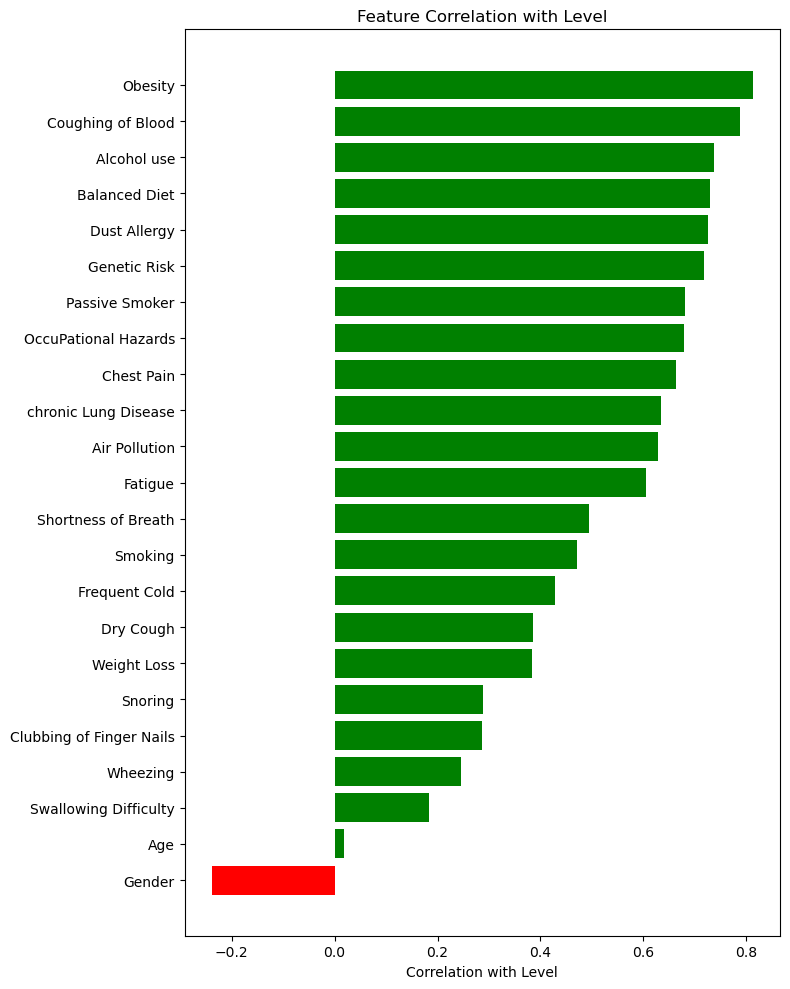

In [17]:
plt.figure(figsize=(8,10))
colors = ["green" if v > 0 else "red" for v in corr_target.values]
plt.barh(corr_target.index, corr_target.values, color=colors)
plt.xlabel(f"Correlation with {target}")
plt.title(f"Feature Correlation with {target}")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## Separation the Features and targets

In [18]:
x=data.iloc[:,:-1].values
y=data.iloc[:,-1]

In [19]:
print(y.shape)
print(x.shape)

(152,)
(152, 23)


## useing train test split to teach the model

In [20]:
x_train,x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify=y)

## Comparing which target each feature maps to.

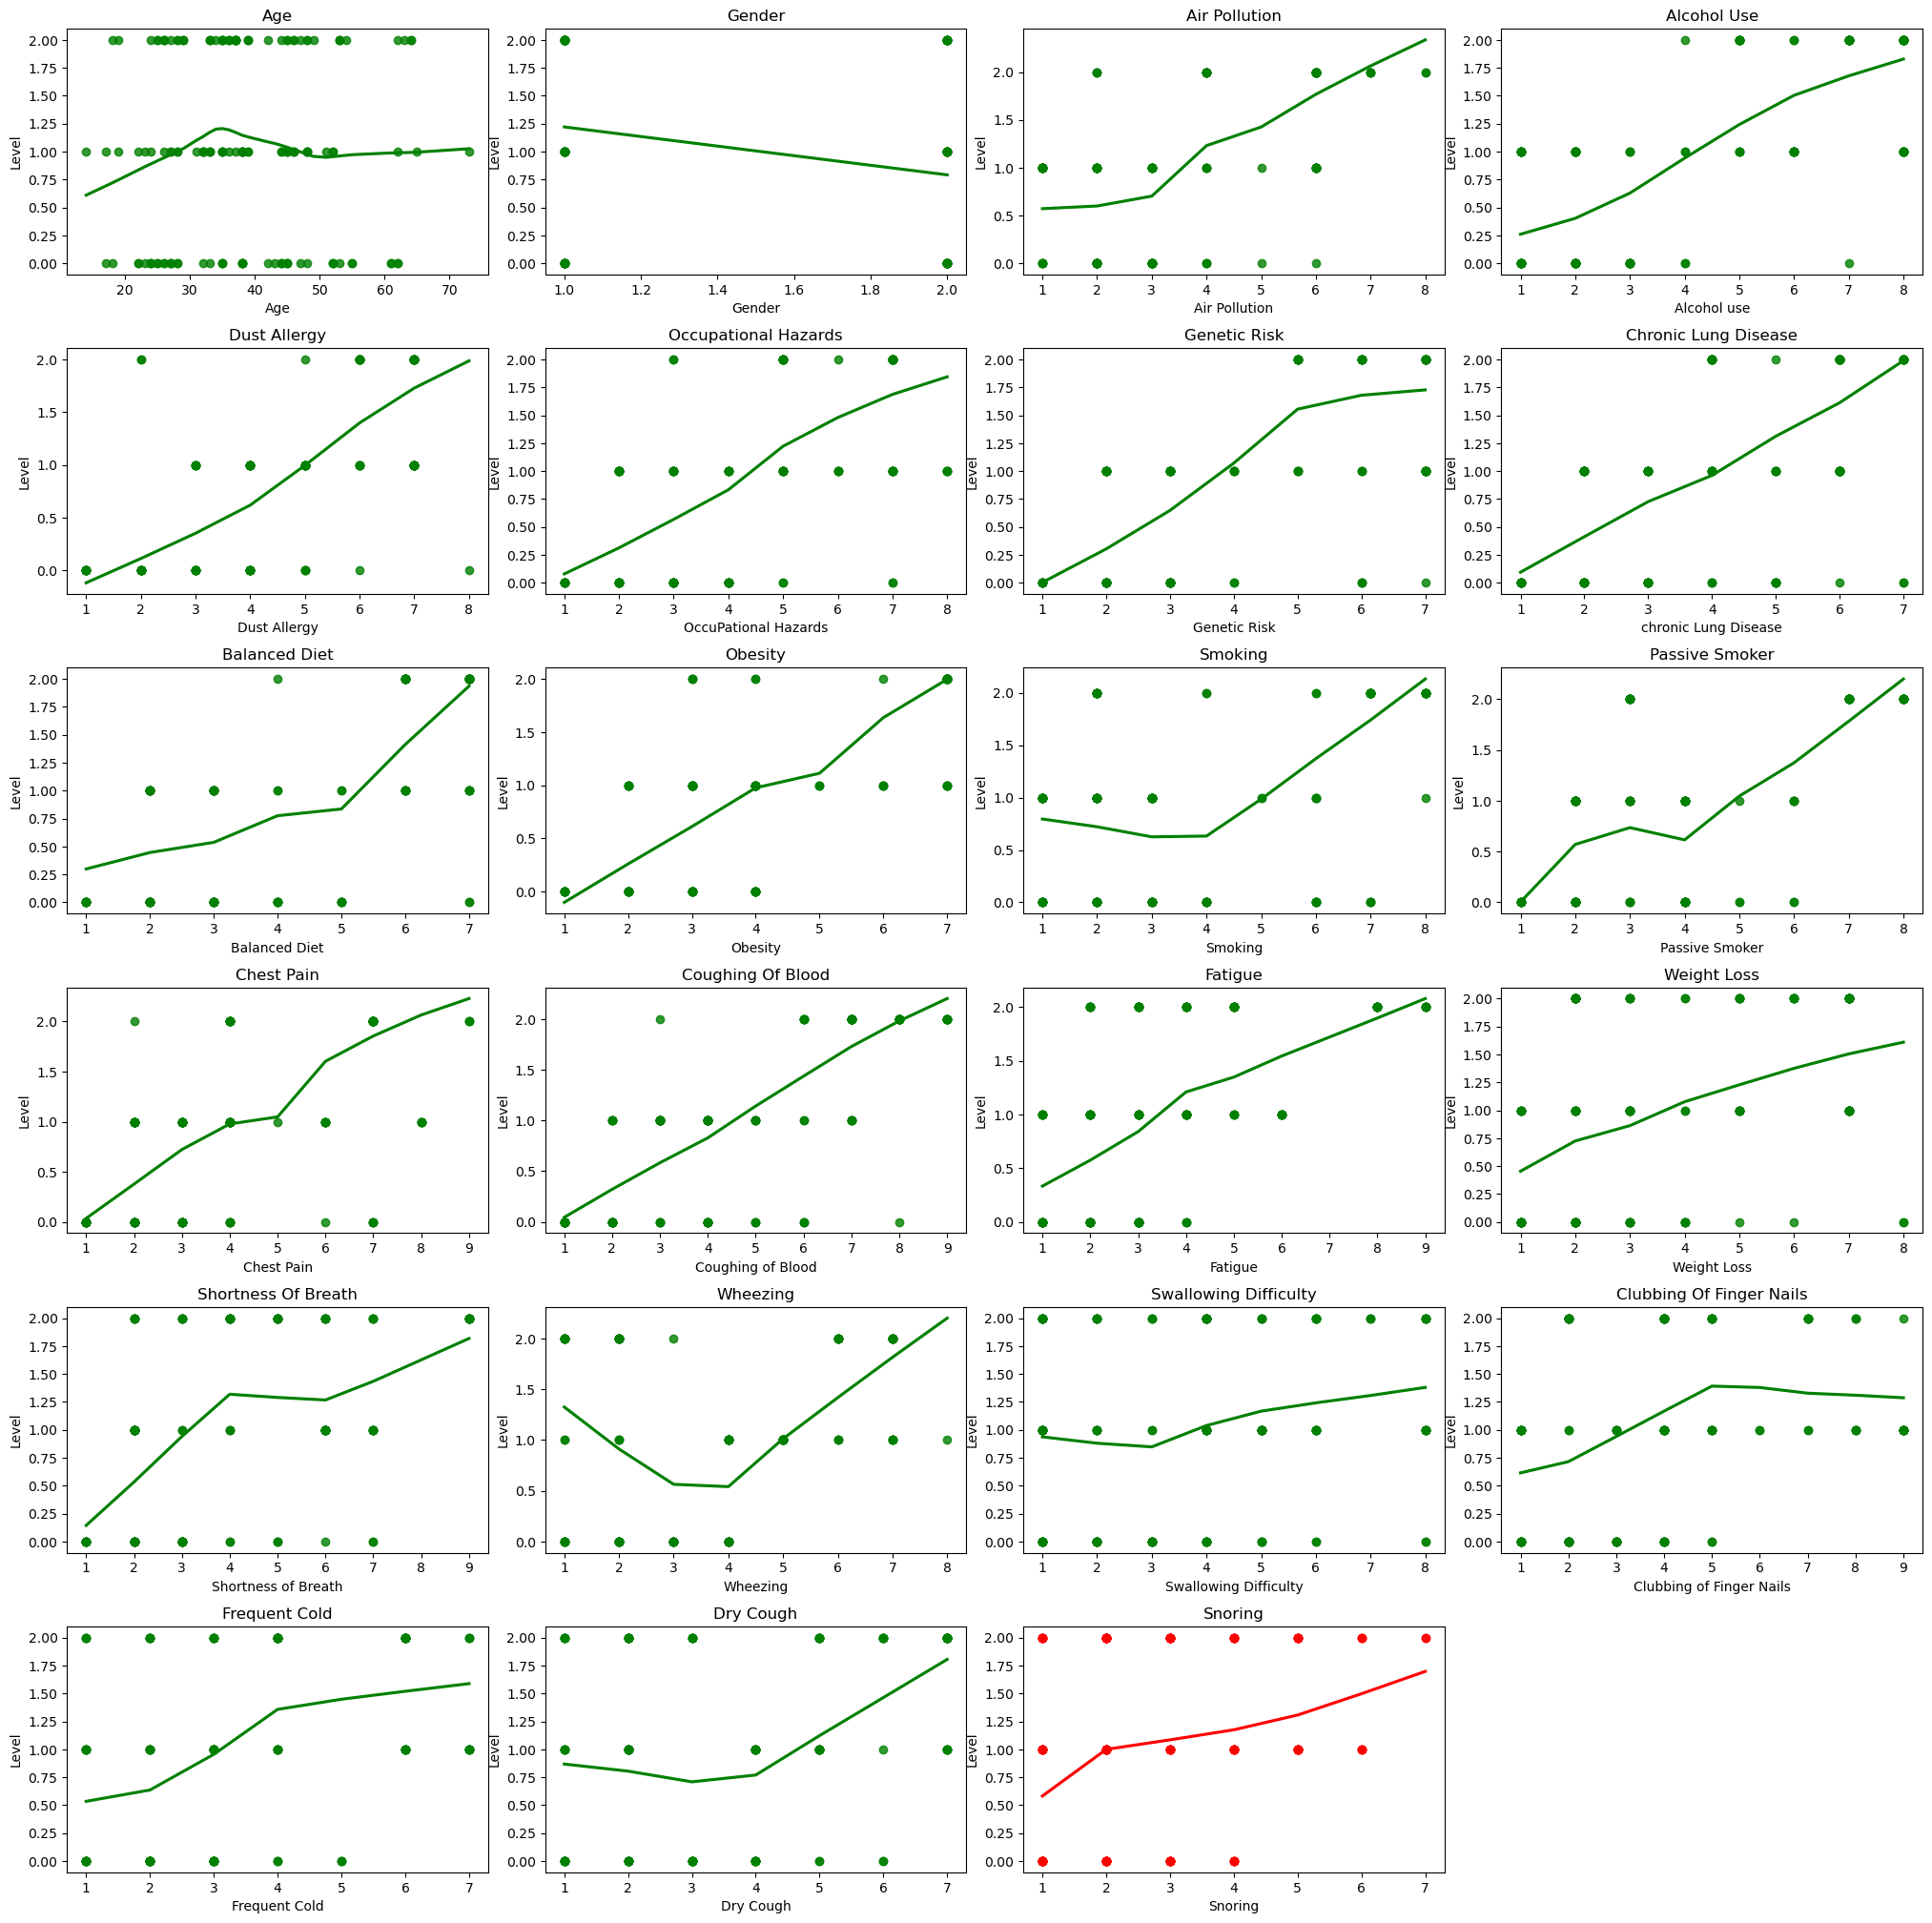

In [21]:
data2=data.copy()
level={'Medium':1,'Low':0,'High':2}
data2["Level"]=data2["Level"].map(level)
fig, ax = plt.subplots(ncols=4, nrows=6, figsize=(20, 20))
ax = ax.flatten()

for i, col in enumerate(data2.columns.drop("Level")):
    sb.regplot(x=col, y='Level', data=data2, lowess=True, color=colors[i], ax=ax[i])
    ax[i].set_title(col.title())

ax[-1].axis("off")

plt.tight_layout(pad=0.1, w_pad=0.6, h_pad=1)
plt.show()

## Histplot for each feature to see thier Quantity

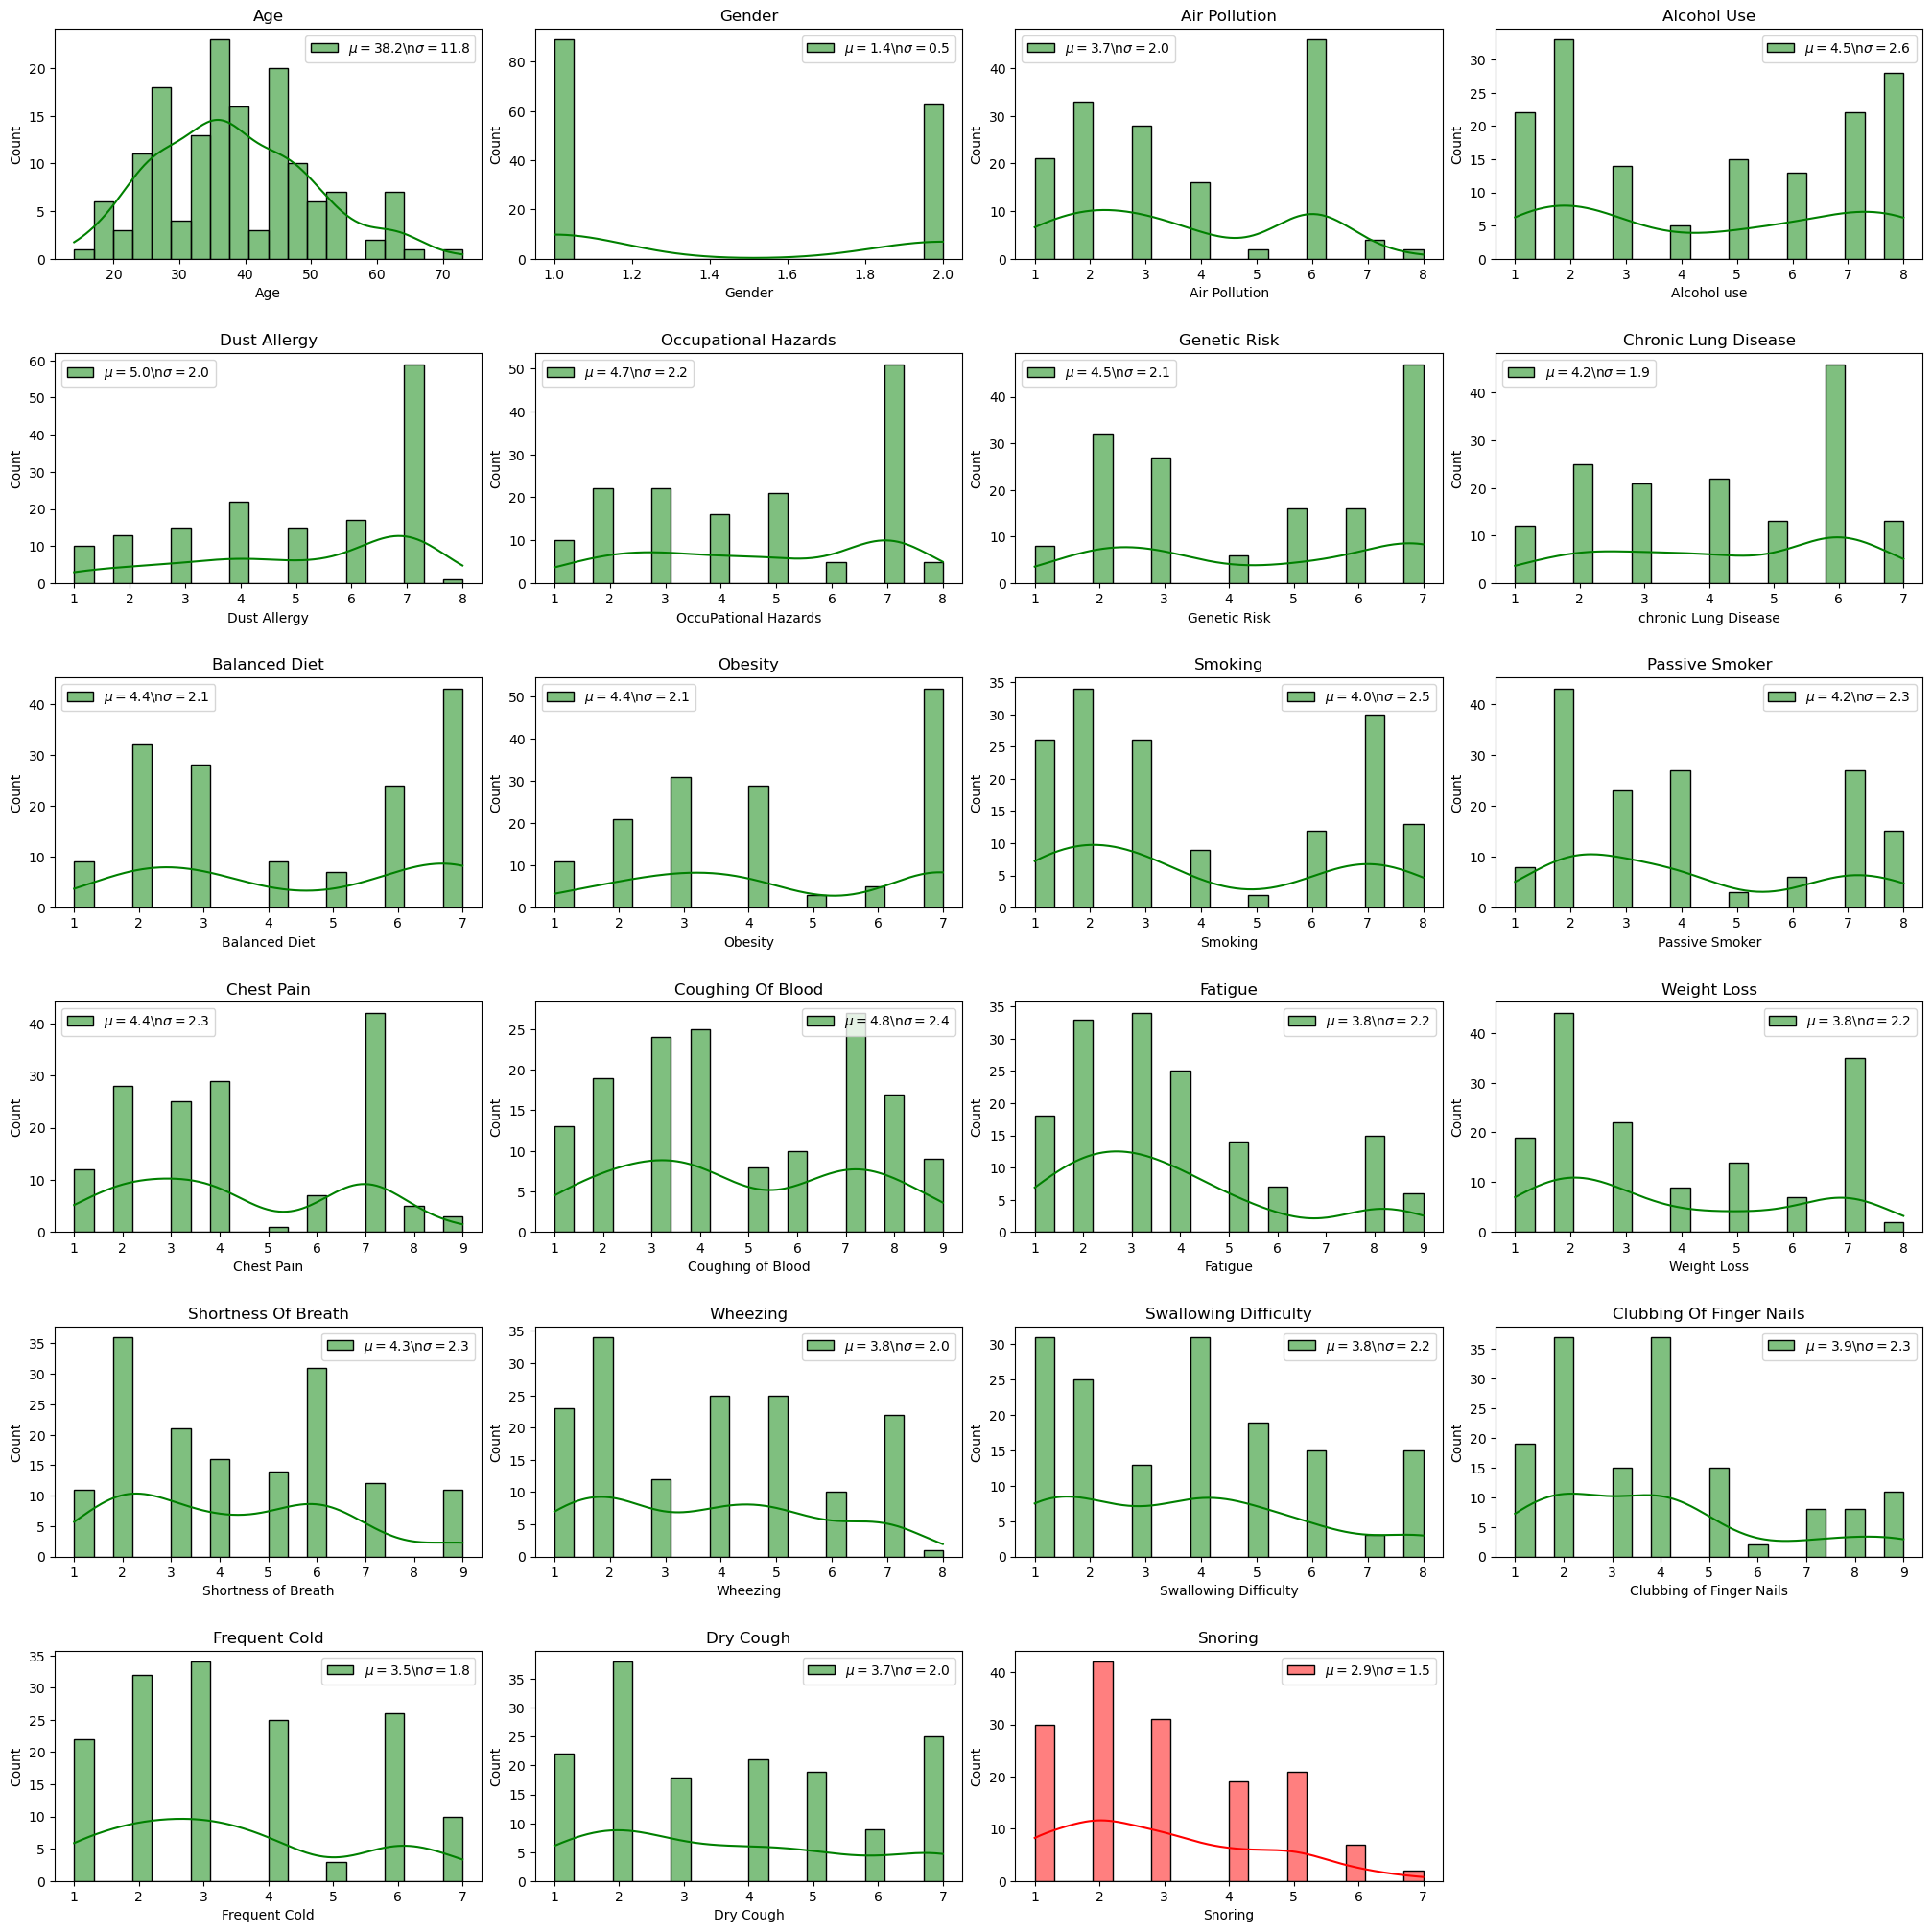

In [22]:
fig, ax = plt.subplots(ncols=4, nrows=6, figsize=(20, 20))
ax = ax.flatten()
i = 0
cols_to_plot = data2.columns.drop("Level")
for i, col in enumerate(cols_to_plot):
    v = data2[col]
    mu, sigma = norm.fit(v)
    sb.histplot(v, kde=True, bins=20, color=colors[i], ax=ax[i],
                label=rf'$\mu={mu:.1f}$\n$\sigma={sigma:.1f}$')
    ax[i].set_title(col.title())
    ax[i].legend()
    i += 1
ax[-1].axis("off")
plt.tight_layout(pad=0.2, w_pad=0.6, h_pad=2.5)
plt.show()

## using standard scaler to have a better performance

In [23]:
scaler = StandardScaler()
x_train_scale = scaler.fit_transform(x_train)
x_test_scale = scaler.transform(x_test)

## Making another y_train to make the target in numbers

In [24]:
y_train2=y_train
level={'Medium':1,'Low':0,'High':2}
y_train2=y_train2.map(level)

## Using DecisionTreeRegressor to see it will see wich feature more important

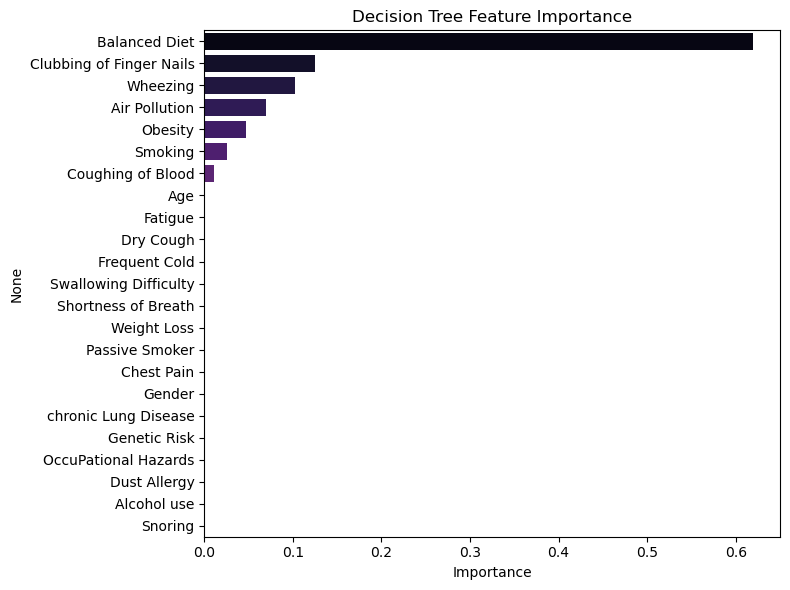

In [25]:
feature_names = data2.iloc[:, :-1].columns
dt = DecisionTreeRegressor(max_depth=8, random_state=42)
dt.fit(x_train, y_train2)

dt_importances = pd.Series(dt.feature_importances_, index=feature_names).sort_values(ascending=False)

plt.figure(figsize=(8,6))
sb.barplot(x=dt_importances.values, y=dt_importances.index, palette="magma")
plt.title("Decision Tree Feature Importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## Comparing The awnsers that correlation and DecisionTreeRegressor gave us
if we look at the bars we can see that they have something in commen:
Ballenced diet  has high effect on the cancer and its very important for our health

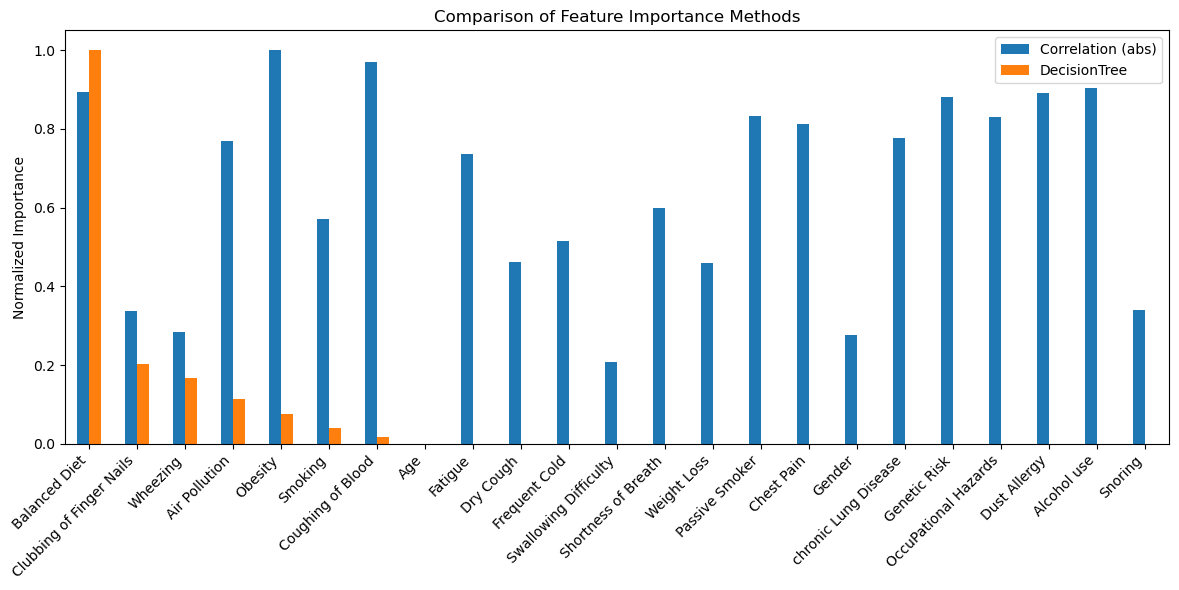

In [26]:
corr_with_target = data2.corr()[target].drop(target).sort_values(key=abs, ascending=False)

compare_df = pd.DataFrame({
    "Correlation (abs)": corr_with_target.abs().reindex(feature_names),
    "DecisionTree": dt_importances.reindex(feature_names)
})

# نرمال‌سازی هر ستون بین 0 و 1 برای مقایسه منصفانه
compare_norm = (compare_df - compare_df.min()) / (compare_df.max() - compare_df.min())

compare_norm.sort_values("DecisionTree", ascending=False).plot(
    kind="bar", figsize=(12,6)
)
plt.title("Comparison of Feature Importance Methods")
plt.ylabel("Normalized Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.legend(loc="upper right")
plt.show()

## Charts for quantity of the levels

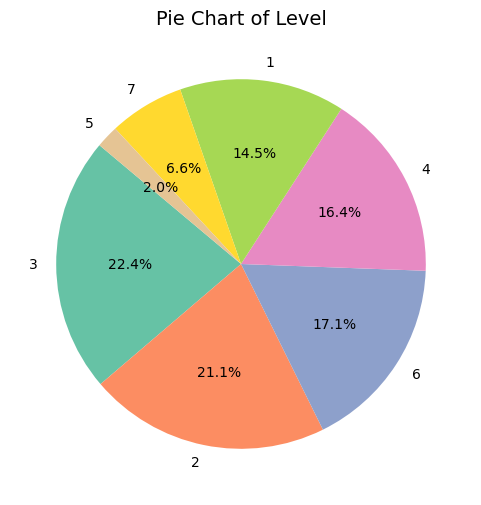

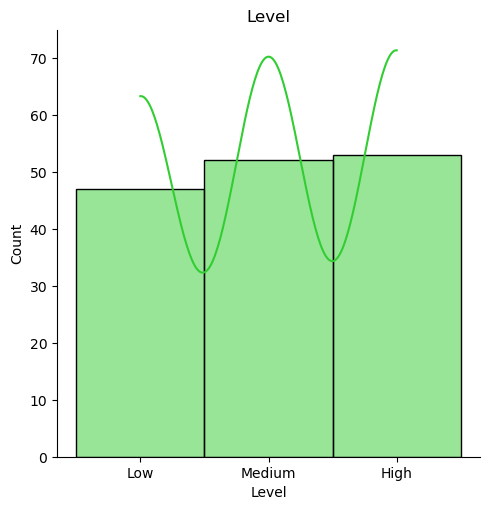

In [27]:
plt.figure(figsize=(6,6))
plt.pie(counts,labels=counts.index,autopct='%1.1f%%',startangle=140,colors=plt.cm.Set2.colors)
plt.title(f"Pie Chart of Level", fontsize=14)
plt.show()

sb.displot(data["Level"],kde=True,bins=10,color="limegreen")
plt.title("Level")
plt.show()

In [28]:
data.columns

Index(['Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy',
       'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease',
       'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain',
       'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath',
       'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails',
       'Frequent Cold', 'Dry Cough', 'Snoring', 'Level'],
      dtype='object')

## Using gridsearch cv to find the best n_neghibor 
as we can see it suggests for the number 6
and it says it will gave us 94% score

In [29]:
p_grid={"n_neighbors":np.arange(3,50)}
knn = KNeighborsClassifier()
knn_cv=GridSearchCV(knn,p_grid,cv=5)
knn_cv.fit(x_train_scale, y_train)
print(knn_cv.best_params_)
print(knn_cv.best_score_)

{'n_neighbors': 6}
0.9423333333333334


## KNN

In [30]:
knn = KNeighborsClassifier(n_neighbors=6)
knn.fit(x_train_scale, y_train)

KNeighborsClassifier(n_neighbors=6)

In [31]:
y_pred = knn.predict(x_test_scale)

## Knn gives us 90.3% accuracy and its really good

In [32]:
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.9032258064516129


In [33]:
cm = confusion_matrix(y_test, y_pred, labels=["Low","Medium","High"])

## confusion matrix shows us that this model had really good predtictions in low and high chances but it was a little weak in medium 

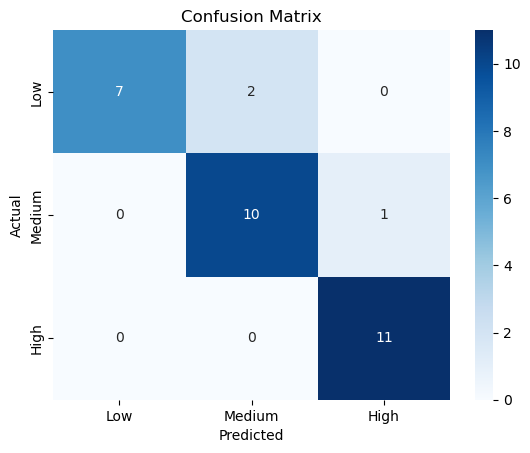

In [34]:
sb.heatmap(cm, annot=True, fmt='d', cmap='Blues',xticklabels=["Low","Medium","High"],yticklabels=["Low","Medium","High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

## classification report shows us that Knn was a success full model

In [35]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

        High       0.92      1.00      0.96        11
         Low       1.00      0.78      0.88         9
      Medium       0.83      0.91      0.87        11

    accuracy                           0.90        31
   macro avg       0.92      0.90      0.90        31
weighted avg       0.91      0.90      0.90        31



In [36]:
accuracy=accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

accuracy: 0.9032258064516129
Precision: 0.9166666666666666
Recall: 0.8956228956228957
F1-score: 0.9003623188405797


## comparing the models performance in different predictions

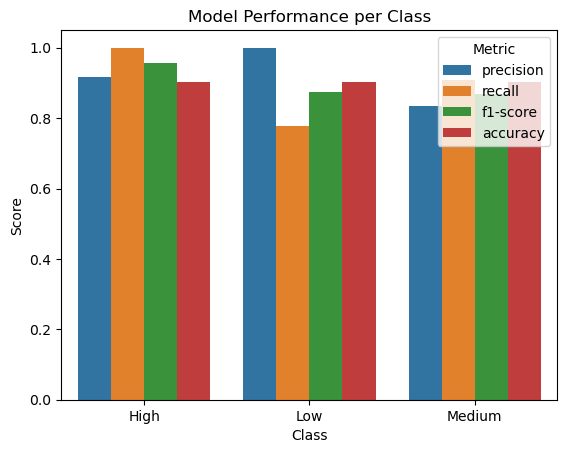

In [37]:
report = classification_report(y_test, y_pred, output_dict=True)
df = pd.DataFrame(report).transpose()
df_plot = df[['precision', 'recall', 'f1-score']].iloc[:-3]
df_plot['accuracy'] = accuracy
df_plot = df_plot.reset_index()

df_melt = df_plot.melt(id_vars='index', var_name='Metric', value_name='Score')

sb.barplot(data=df_melt, x='index', y='Score', hue='Metric')

plt.title("Model Performance per Class")
plt.xlabel("Class")
plt.ylabel("Score")
plt.show()

## DecisionTree 

In [38]:
dt = DecisionTreeClassifier(max_depth=5,random_state=42)
dt.fit(x_train, y_train)

y_pred = dt.predict(x_test)

## classification report shows us that DecisionTree was a success full

In [39]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 1.0
              precision    recall  f1-score   support

        High       1.00      1.00      1.00        11
         Low       1.00      1.00      1.00         9
      Medium       1.00      1.00      1.00        11

    accuracy                           1.00        31
   macro avg       1.00      1.00      1.00        31
weighted avg       1.00      1.00      1.00        31



## confusion matrix shows us that this model had really good predtictions in all predictions and it was the best

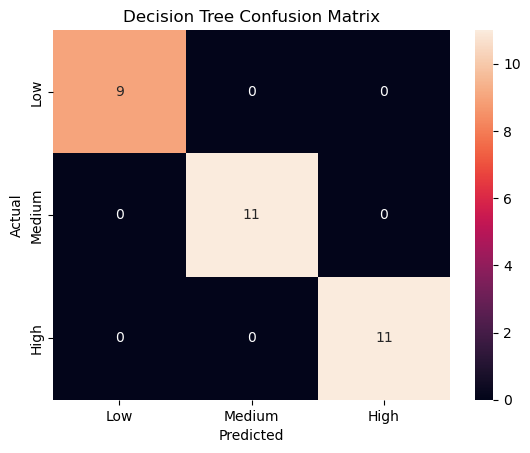

In [40]:
cm = confusion_matrix(y_test, y_pred, labels=["Low","Medium","High"])

sb.heatmap(cm, annot=True, fmt='d', xticklabels=["Low","Medium","High"], yticklabels=["Low","Medium","High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")
plt.show()

## DecisionTrees plot

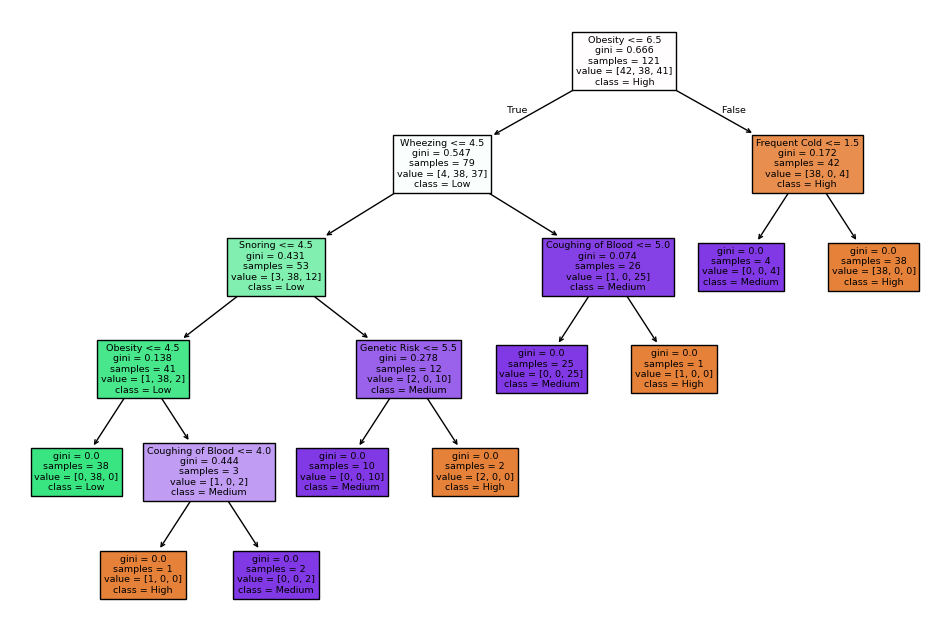

In [41]:
plt.figure(figsize=(12,8))
plot_tree(dt, filled=True, feature_names=feature_names, class_names=["High","Low","Medium"])
plt.show()

In [42]:
accuracy=accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1-score: 1.0


## comparing the models performance in different predictions

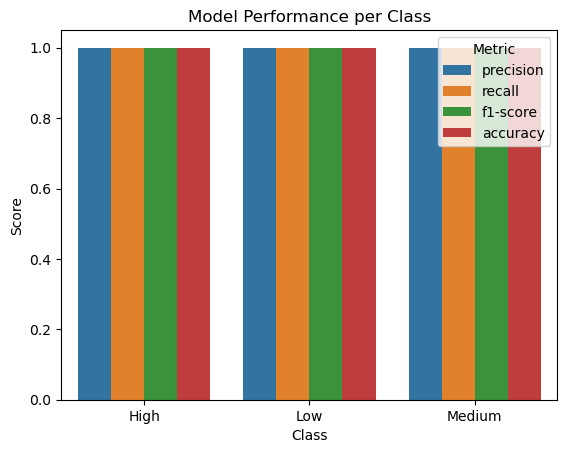

In [43]:
report = classification_report(y_test, y_pred, output_dict=True)
df = pd.DataFrame(report).transpose()
df_plot = df[['precision', 'recall', 'f1-score']].iloc[:-3]
df_plot['accuracy'] = accuracy
df_plot = df_plot.reset_index()

df_melt = df_plot.melt(id_vars='index', var_name='Metric', value_name='Score')

sb.barplot(data=df_melt, x='index', y='Score', hue='Metric')

plt.title("Model Performance per Class")
plt.xlabel("Class")
plt.ylabel("Score")
plt.show()

## svm

In [44]:
svm = SVC()
svm.fit(x_train_scale, y_train)

SVC()

In [45]:
y_pred = svm.predict(x_test_scale)

 ## classification report shows us that svm was a success full model but not as much as knn

In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Accuracy: 0.9032258064516129
              precision    recall  f1-score   support

        High       0.92      1.00      0.96        11
         Low       1.00      0.78      0.88         9
      Medium       0.83      0.91      0.87        11

    accuracy                           0.90        31
   macro avg       0.92      0.90      0.90        31
weighted avg       0.91      0.90      0.90        31



In [47]:
cm = confusion_matrix(y_test, y_pred, labels=["Low","Medium","High"])

## confusion matrix shows us that this model had really good predtictions in low and high chances but it was a little weak in medium 

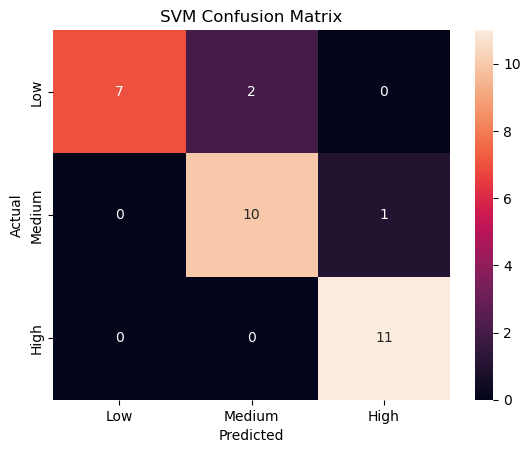

In [48]:
sb.heatmap(cm, annot=True, fmt='d', xticklabels=["Low","Medium","High"], yticklabels=["Low","Medium","High"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("SVM Confusion Matrix")
plt.show()

In [49]:
accuracy=accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, average='macro')
recall = recall_score(y_test, y_pred, average='macro')
f1 = f1_score(y_test, y_pred, average='macro')

print("accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("F1-score:", f1)

accuracy: 0.9032258064516129
Precision: 0.9166666666666666
Recall: 0.8956228956228957
F1-score: 0.9003623188405797


## comparing the models performance in different predictions

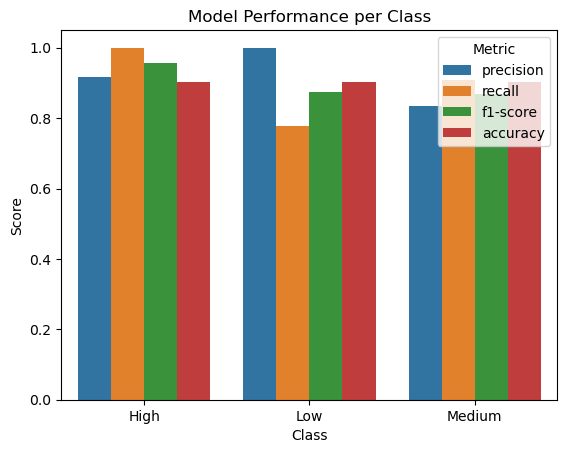

In [50]:
report = classification_report(y_test, y_pred, output_dict=True)
df = pd.DataFrame(report).transpose()
df_plot = df[['precision', 'recall', 'f1-score']].iloc[:-3]
df_plot['accuracy'] = accuracy
df_plot = df_plot.reset_index()

df_melt = df_plot.melt(id_vars='index', var_name='Metric', value_name='Score')

sb.barplot(data=df_melt, x='index', y='Score', hue='Metric')

plt.title("Model Performance per Class")
plt.xlabel("Class")
plt.ylabel("Score")
plt.show()

In [51]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

knn_scores = cross_val_score(KNeighborsClassifier(n_neighbors=6), scaler.fit_transform(x), y, cv=cv)
dt_scores  = cross_val_score(DecisionTreeClassifier(max_depth=5, random_state=42), x, y, cv=cv)
svm_scores = cross_val_score(SVC(), scaler.fit_transform(x), y, cv=cv)

print("KNN:", knn_scores.round(3), "→ mean:", knn_scores.mean().round(3))
print("DT :", dt_scores.round(3), "→ mean:", dt_scores.mean().round(3))
print("SVM:", svm_scores.round(3), "→ mean:", svm_scores.mean().round(3))

KNN: [1.    0.839 0.967 0.933 0.933] → mean: 0.934
DT : [1.  1.  1.  0.9 0.9] → mean: 0.96
SVM: [1.    0.903 0.933 0.967 0.933] → mean: 0.947


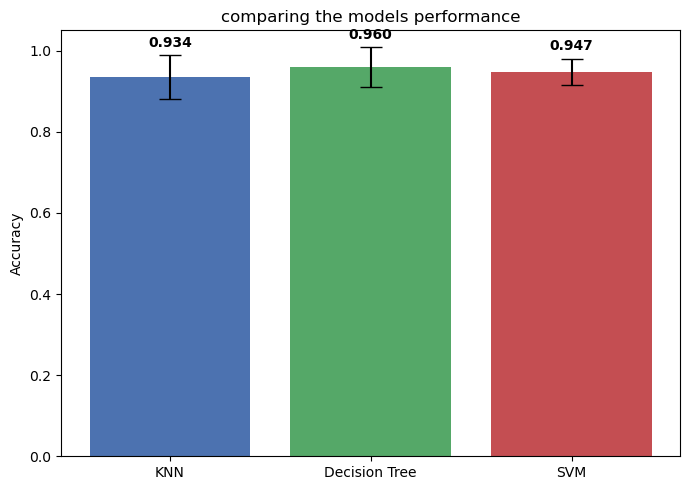

In [52]:
model_names = ["KNN", "Decision Tree", "SVM"]
means = [knn_scores.mean(), dt_scores.mean(), svm_scores.mean()]
stds = [knn_scores.std(), dt_scores.std(), svm_scores.std()]

plt.figure(figsize=(7,5))
plt.bar(model_names, means, yerr=stds, capsize=8, color=["#4C72B0","#55A868","#C44E52"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("comparing the models performance")
for i, v in enumerate(means):
    plt.text(i, v + stds[i] + 0.02, f"{v:.3f}", ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

In [53]:
print(data.columns)

Index(['Age', 'Gender', 'Air Pollution', 'Alcohol use', 'Dust Allergy',
       'OccuPational Hazards', 'Genetic Risk', 'chronic Lung Disease',
       'Balanced Diet', 'Obesity', 'Smoking', 'Passive Smoker', 'Chest Pain',
       'Coughing of Blood', 'Fatigue', 'Weight Loss', 'Shortness of Breath',
       'Wheezing', 'Swallowing Difficulty', 'Clubbing of Finger Nails',
       'Frequent Cold', 'Dry Cough', 'Snoring', 'Level'],
      dtype='object')


## Run the app to do a test by your self

In [54]:

columns = data.columns.tolist()

target_col = "Level"
features = [col for col in columns if col != target_col]


input_config = {
    "Age": "entry",

    "Gender": ["Male", "Female"],

    "Air Pollution": [1,2,3,4,5,6,7,8],
    "Alcohol use": [1,2,3,4,5,6,7,8],
    "Dust Allergy": [1,2,3,4,5,6,7,8],
    "OccuPational Hazards": [1,2,3,4,5,6,7,8],
    "Genetic Risk": [1,2,3,4,5,6,7],
    "chronic Lung Disease": [1,2,3,4,5,6,7],
    "Balanced Diet": [1,2,3,4,5,6,7],
    "Obesity": [1,2,3,4,5,6,7],
    "Smoking": [1,2,3,4,5,6,7,8],
    "Passive Smoker": [1,2,3,4,5,6,7,8],
    "Chest Pain": [1,2,3,4,5,6,7,8,9],
    "Coughing of Blood": [1,2,3,4,5,6,7,8,9],
    "Fatigue": [1,2,3,4,5,6,7,8,9],
    "Weight Loss": [1,2,3,4,5,6,7,8],
    "Shortness of Breath": [1,2,3,4,5,6,7,8,9],
    "Wheezing": [1,2,3,4,5,6,7,8],
    "Swallowing Difficulty": [1,2,3,4,5,6,7,8],
    "Clubbing of Finger Nails": [1,2,3,4,5,6,7,8,9],
    "Frequent Cold": [1,2,3,4,5,6,7],
    "Dry Cough": [1,2,3,4,5,6,7],
    "Snoring": [1,2,3,4,5,6,7]
}


def convert_value(col, val):
    if col == "Gender":
        return 1 if val == "Male" else 2
    return float(val)


root = tk.Tk()
root.title("Cancer Prediction App")
root.geometry("500x700")


tk.Label(root, text="Select Model", font=("Arial", 12)).pack()

model_var = tk.StringVar()
model_combo = ttk.Combobox(root, textvariable=model_var)
model_combo['values'] = ("KNN", "SVM", "Decision Tree (BEST)")
model_combo.pack(pady=10)


canvas = tk.Canvas(root)
scrollbar = ttk.Scrollbar(root, orient="vertical", command=canvas.yview)
frame = tk.Frame(canvas)

frame.bind(
    "<Configure>",
    lambda e: canvas.configure(scrollregion=canvas.bbox("all"))
)

canvas.create_window((0, 0), window=frame, anchor="nw")
canvas.configure(yscrollcommand=scrollbar.set)

canvas.pack(side="left", fill="both", expand=True)
scrollbar.pack(side="right", fill="y")


inputs = {}

for col in features:
    tk.Label(frame, text=col).pack()

    config = input_config.get(col, [1,2,3,4,5])

    if config == "entry":
        var = tk.StringVar()
        entry = tk.Entry(frame, textvariable=var)
        entry.pack(pady=3)
        inputs[col] = var

    else:
        var = tk.StringVar()
        combo = ttk.Combobox(frame, textvariable=var)
        combo['values'] = config
        combo.pack(pady=3)
        inputs[col] = var


def predict():
    try:
        model_name = model_var.get()

        if model_name == "":
            messagebox.showerror("Error", "Select a model!")
            return


        if model_name == "KNN":
            model = knn
        elif model_name == "SVM":
            model = svm
        else:
            model = dt



        values = []

        for col in features:
            val = inputs[col].get()

            if val == "":
                messagebox.showerror("Error", f"Fill {col}")
                return

            values.append(convert_value(col, val))

        X = np.array([values])


        X = scaler.transform(X)

        pred = model.predict(X)[0]


        if pred == "High":
            result_label.config(text=f"Prediction: {pred}", fg="red")
        elif pred == "Medium":
            result_label.config(text=f"Prediction: {pred}", fg="orange")
        else:
            result_label.config(text=f"Prediction: {pred}", fg="green")

    except Exception as e:
        messagebox.showerror("Error", str(e))


tk.Button(root, text="Predict", command=predict, bg="green", fg="white").pack(pady=20)


result_label = tk.Label(root, text="", font=("Arial", 14))
result_label.pack()

root.mainloop()